# 01 · Análisis Exploratorio de Datos (EDA)
**Proyecto:** Ranking de Fans UFC · **Etapa 1:** Diagnóstico

### ¿Para qué sirve este notebook?
En la Etapa 1 tenemos que **diagnosticar** la situación de datos de nuestra organización
(el grupo de fans que mira cada evento de la UFC). Este análisis exploratorio aporta la
**evidencia**: no decimos "los datos son un lío" por intuición, lo mostramos con números.

Responde tres preguntas:
1. **¿Qué datos tenemos?** Inventario de las tablas de UFCStats.
2. **¿Qué tan confiables son?** Problemas de calidad encontrados (hallazgos H1 a H7).
3. **¿Qué nos dicen de las 8 categorías masculinas?** Volumen, forma de ganar y actividad,
   que después van a ser las variables del ranking.

> Si los datos no están descargados, la primera celda los baja y limpia sola.

In [1]:
# --- Librerías ---
import json                       # para leer el archivo de metadatos de la descarga (.json)
import pandas as pd               # pandas: la librería para trabajar con tablas (DataFrames)
import matplotlib.pyplot as plt   # matplotlib: la librería para hacer gráficos
from pathlib import Path          # Path: para manejar rutas de carpetas sin importar el sistema operativo

# --- Encontrar la carpeta del proyecto ---
def encontrar_raiz():                                   # función que busca la carpeta raíz del proyecto
    aqui = Path.cwd().resolve()                         # carpeta desde donde se está ejecutando el notebook
    candidatos = [aqui, *aqui.parents]                  # candidatas: esta carpeta y todas las de "arriba"
    candidatos += [p for p in aqui.iterdir() if p.is_dir()]  # ...y también las subcarpetas de esta
    for c in candidatos:                                # recorremos cada carpeta candidata
        if (c / "src" / "limpieza.py").exists():        # la raíz es la que contiene src/limpieza.py
            return c                                    # la encontramos: la devolvemos
    raise FileNotFoundError("No encuentro la carpeta del proyecto (la que tiene src/limpieza.py).")  # no estaba

RAIZ = encontrar_raiz()                 # guardamos la carpeta raíz del proyecto
RAW = RAIZ / "data" / "raw"             # carpeta de datos crudos (tal cual vienen de UFCStats)
PROC = RAIZ / "data" / "processed"      # carpeta de datos limpios (los genera limpieza.py)
print("✅ Carpeta del proyecto encontrada")    # confirmamos que encontró la carpeta

# --- Si faltan los datos, se descargan y limpian solos ---
falta_raw = not (RAW / "ufc_fight_results.csv").exists()   # ¿falta la tabla cruda de resultados?
falta_proc = not (PROC / "peleas.csv").exists()            # ¿falta la tabla limpia de peleas?
if falta_raw or falta_proc:                                # si falta cualquiera de las dos...
    import subprocess, sys                                 # herramientas para ejecutar otros scripts de Python
    print("Faltan los datos: descargando y limpiando (tarda unos segundos)...")  # aviso
    for script in ["descargar_datos.py", "limpieza.py"]:   # primero descarga, después limpieza
        subprocess.run([sys.executable, str(RAIZ / "src" / script)], check=True)  # ejecuta el script

# --- Estilo de los gráficos ---
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#a3a29c"   # colores de las barras y líneas
TINTA, TINTA_2 = "#0b0b0b", "#52514e"                   # colores de texto: principal y secundario
plt.rcParams.update({                    # configuramos el estilo por defecto de todos los gráficos:
    "figure.figsize": (9, 4),            # tamaño del gráfico (ancho, alto) en pulgadas
    "axes.spines.top": False,            # sin borde de arriba
    "axes.spines.right": False,          # sin borde de la derecha
    "axes.edgecolor": "#d0cfca",         # color gris suave para los bordes que quedan
    "axes.labelcolor": TINTA_2,          # color de los nombres de los ejes
    "xtick.color": TINTA_2,              # color de los números del eje X
    "ytick.color": TINTA_2,              # color de los números del eje Y
    "axes.titleweight": "bold",          # títulos en negrita
    "axes.titlesize": 12,                # tamaño de los títulos
    "axes.titlelocation": "left",        # títulos alineados a la izquierda
    "axes.grid": True,                   # mostrar líneas de guía (grilla)
    "grid.color": "#ecebe7",             # grilla en gris muy claro
    "grid.linewidth": 0.8,               # grilla finita
    "axes.axisbelow": True})             # la grilla va por detrás de las barras

# Las 8 categorías masculinas, de la más liviana a la más pesada (este orden se usa en todos los gráficos)
MASCULINAS = ["Mosca", "Gallo", "Pluma", "Ligero", "Wélter", "Mediano", "Semipesado", "Pesado"]

✅ Carpeta del proyecto encontrada


## 1. ¿Qué datos tenemos?

**Fuente:** UFCStats.com, el sitio oficial de estadísticas de la UFC. Lo tomamos de un
repositorio público de GitHub que lo scrapea a diario, así no hacemos miles de pedidos al sitio.

**Fecha de corte:** el ranking es una *foto* de un momento. La fecha de corte es la del
último evento incluido. Volver a correr la descarga actualiza todo.

In [2]:
eventos = pd.read_csv(RAW / "ufc_event_details.csv")     # tabla de eventos: nombre, fecha, lugar
resultados = pd.read_csv(RAW / "ufc_fight_results.csv")  # tabla de resultados: quién ganó, cómo, categoría
stats = pd.read_csv(RAW / "ufc_fight_stats.csv")         # estadísticas por round (golpes, derribos...)
fisico = pd.read_csv(RAW / "ufc_fighter_tott.csv")       # datos físicos: altura, peso, alcance, nacimiento
texto_meta = (RAW / "metadata_descarga.json").read_text(encoding="utf-8")  # leemos el archivo de metadatos
meta = json.loads(texto_meta)                             # lo convertimos en un diccionario de Python

fechas = pd.to_datetime(eventos["DATE"].str.strip(), format="%B %d, %Y")  # texto "November 14, 2026" -> fecha
FECHA_CORTE = fechas.max()                                # la fecha más reciente = nuestra fecha de corte
print("Descarga:", meta["fecha_descarga"])                # cuándo se bajaron los datos
print("Primer evento:", fechas.min().date())              # el evento más antiguo (UFC 1, 1994)
print("Último evento (FECHA DE CORTE):", FECHA_CORTE.date())  # el evento más reciente
print("Último evento incluido:", eventos.loc[fechas.idxmax(), "EVENT"].strip())  # nombre de ese evento

filas_inventario = []                                     # lista vacía donde juntamos una fila por tabla
for nombre, datos in meta["tablas"].items():              # recorremos cada tabla descargada
    n_filas = len(pd.read_csv(RAW / f"{nombre}.csv"))      # contamos cuántas filas tiene
    filas_inventario.append({"tabla": nombre,              # nombre del archivo
                             "filas": n_filas,             # cantidad de filas
                             "qué contiene": datos["descripcion"]})  # descripción en castellano
inventario = pd.DataFrame(filas_inventario)               # convertimos la lista en una tabla
inventario                                                # la mostramos (última línea de la celda = se muestra)

Descarga: 2026-11-16T15:45:56
Primer evento: 1994-03-11
Último evento (FECHA DE CORTE): 2026-11-14
Último evento incluido: UFC 334: Gane vs. Hokit


,tabla,filas,qué contiene
0,ufc_event_details,797,"Eventos: nombre, fecha y lugar"
1,ufc_fight_details,9028,"Peleas: evento, cruce y link a la pelea"
2,ufc_fight_results,9028,"Resultados: ganador, método, round, categoría"
3,ufc_fight_stats,42428,"Estadísticas por round y por peleador (golpes,..."
4,ufc_fighter_details,4628,"Peleadores: nombre, apellido, apodo"
5,ufc_fighter_tott,4629,"Físico del peleador: altura, peso, alcance, gu..."


**Lectura:** tenemos toda la historia de la UFC, desde 1994 hasta el último evento.
Para el ranking la tabla clave es **resultados** (quién le ganó a quién, cómo y cuándo).
Las estadísticas de golpes y derribos quedan como posible complemento.

## 2. ¿Qué tan confiables son los datos? Hallazgos de calidad

Revisamos los problemas típicos: **duplicados, huecos, fuentes que no coinciden e
identificadores ambiguos**. Cada hallazgo tiene un número (H1, H2…) para citarlo en el video.

### H1 · Espacios invisibles al final de los textos

In [3]:
nombres_originales = resultados["EVENT"]                      # la columna de nombres de evento, tal cual viene
nombres_limpios = resultados["EVENT"].str.strip()              # la misma columna sin espacios al principio/final
con_espacio = (nombres_originales != nombres_limpios).mean()   # proporción de nombres que cambiaron al limpiar
print(f"Nombres de evento con espacio al final: {con_espacio:.0%}")  # lo mostramos como porcentaje
print(repr(resultados["EVENT"].iloc[0]), "vs", repr(eventos["EVENT"].iloc[0]))  # repr() deja ver el espacio

Nombres de evento con espacio al final: 100%
'UFC 334: Gane vs. Hokit ' vs 'UFC 334: Gane vs. Hokit'


**Por qué importa:** para la computadora `'UFC 334 '` y `'UFC 334'` son cosas distintas.
Sin limpiar, no podríamos ponerle fecha a **ninguna** pelea.
**Solución:** quitar espacios al principio y al final de todos los textos (`limpieza.py`).

### H2 · Peleas duplicadas porque el evento cambió de nombre

In [4]:
es_repetida = resultados["URL"].duplicated(keep=False)     # True en TODAS las filas cuyo link de pelea se repite
dups = resultados[es_repetida].copy()                      # nos quedamos solo con esas filas
dups["EVENT"] = dups["EVENT"].str.strip()                  # limpiamos espacios para comparar bien los nombres
print("Peleas que aparecen dos veces:", resultados["URL"].duplicated().sum())  # cuántas copias sobran

por_pelea = dups.groupby("URL")["EVENT"]                   # agrupamos las filas repetidas por pelea (URL)
nombres_por_pelea = por_pelea.apply(lambda s: " | ".join(sorted(set(s))))  # los nombres de evento de cada una
nombres_por_pelea.value_counts()                           # contamos: así vemos qué eventos están duplicados

Peleas que aparecen dos veces: 25


EVENT
Noche UFC: Lopes vs. Silva | UFC Fight Night: Lopes vs. Silva                    14
Noche UFC: Grasso vs. Shevchenko 2 | UFC Fight Night: Grasso vs. Shevchenko 2    11
Name: count, dtype: int64

**Por qué importa:** la misma pelea aparece dos veces (una como *UFC Fight Night* y otra como
*Noche UFC*). Contada doble, el ganador sumaría dos victorias por una sola pelea.
**Solución:** cada pelea tiene un link único (URL); se conserva una sola copia.

### H3 · Un evento sin fecha

In [5]:
eventos_en_resultados = set(resultados["EVENT"].str.strip())  # nombres de evento que aparecen en resultados
eventos_en_tabla = set(eventos["EVENT"].str.strip())          # nombres de evento de la tabla de eventos
sin_fecha = eventos_en_resultados - eventos_en_tabla          # los que están en resultados pero no en eventos
for ev in sorted(sin_fecha):                                  # recorremos cada uno, en orden alfabético
    cantidad = (resultados["EVENT"].str.strip() == ev).sum()  # cuántas peleas tiene ese evento
    print(f"{ev:45s} -> {cantidad} peleas")                   # lo mostramos alineado

UFC - Road to UFC 4.6                         -> 2 peleas
UFC Fight Night: Grasso vs. Shevchenko 2      -> 11 peleas
UFC Fight Night: Lopes vs. Silva              -> 14 peleas


**Por qué importa:** dos de esos tres son los renombrados de H2 (se resuelven solos).
*Road to UFC 4.6* no figura en la tabla de eventos: sus peleas quedan sin fecha.
**Solución:** al ser un torneo de desarrollo y solo 2 peleas, se excluyen del ranking
y se deja registrado.

### H4 · Datos faltantes 'disfrazados'

In [6]:
columnas = ["HEIGHT", "WEIGHT", "REACH", "DOB"]                 # altura, peso, alcance, fecha de nacimiento
sin_espacios = fisico[columnas].apply(lambda c: c.str.strip())  # quitamos espacios en las 4 columnas
faltan_guion = (sin_espacios == "--").sum()                     # cuántas celdas dicen "--" (faltante disfrazado)
faltan_vacio = fisico[columnas].isna().sum()                    # cuántas celdas están vacías de verdad
faltantes = pd.DataFrame({"faltan (como '--')": faltan_guion,   # armamos una tabla con los dos conteos
                          "faltan (vacío)": faltan_vacio})
total_faltante = faltantes.sum(axis=1)                          # sumamos las dos columnas, fila por fila
faltantes["% del total"] = (total_faltante / len(fisico) * 100).round(1)  # porcentaje sobre todos los peleadores
faltantes.index = ["Altura", "Peso", "Alcance", "Fecha de nacimiento"]    # nombres de fila en castellano
faltantes                                                       # mostramos la tabla

,faltan (como '--'),faltan (vacío),% del total
Altura,517,0,11.2
Peso,90,0,1.9
Alcance,2139,0,46.2
Fecha de nacimiento,779,0,16.8


**Por qué importa:** el sitio pone `--` cuando no tiene el dato. Para pandas `--` es un
texto válido y no lo cuenta como faltante. **Casi la mitad de los peleadores no tiene
alcance cargado.**
**Decisión:** el ranking **no usa datos físicos**, solo resultados de peleas, que están completos.

### H5 · Homónimos: dos peleadores distintos con el mismo nombre

In [7]:
nombre_repetido = fisico["FIGHTER"].duplicated(keep=False)        # True en cada fila cuyo nombre aparece más de una vez
homonimos = fisico[nombre_repetido].sort_values("FIGHTER")         # esas filas, ordenadas por nombre (quedan juntas)
print("Nombres repetidos:", homonimos["FIGHTER"].nunique())        # cuántos nombres distintos se repiten
homonimos[["FIGHTER", "HEIGHT", "WEIGHT", "DOB"]]                  # mostramos nombre, altura, peso y nacimiento

Nombres repetidos: 9


,FIGHTER,HEIGHT,WEIGHT,DOB
1201,Anthony Figueroa,"5' 4""",135 lbs.,--
4518,Anthony Figueroa,--,155 lbs.,--
4627,Anthony Romero,"5' 5""",145 lbs.,--
3391,Anthony Romero,"5' 11""",155 lbs.,"Feb 25, 1997"
3693,Bruno Silva,"6' 0""",185 lbs.,"Jul 13, 1989"
3692,Bruno Silva,"5' 4""",125 lbs.,"Mar 16, 1990"
3703,Jean Silva,"5' 7""",145 lbs.,"Dec 27, 1996"
3678,Jean Silva,"5' 6""",160 lbs.,"Oct 08, 1977"
1409,Joey Gomez,"5' 10""",135 lbs.,"Jul 21, 1986"
1411,Joey Gomez,"5' 10""",155 lbs.,"Aug 29, 1989"


**Por qué importa:** la tabla de resultados identifica a los peleadores **solo por nombre**,
sin un código único. Hay dos *Bruno Silva* (uno mediano y otro mosca) y dos *Jean Silva*.
Si los mezclamos, sumamos las peleas de uno al otro. Es el problema de calidad más serio,
porque **no da error: da un resultado incorrecto sin avisar**.
**Solución:** separar los homónimos según la categoría en la que pelean (se ve más abajo
cuáles siguen activos).

### H6 · Muchas etiquetas para pocas categorías

In [8]:
categorias = resultados["WEIGHTCLASS"].str.strip()                   # la columna de categoría, sin espacios
print("Etiquetas distintas de categoría:", categorias.nunique())     # cuántas variantes distintas hay
categorias.value_counts().head(12)                                   # las 12 más frecuentes, con su cantidad

Etiquetas distintas de categoría: 120


WEIGHTCLASS
Lightweight Bout             1447
Welterweight Bout            1363
Middleweight Bout            1132
Featherweight Bout            868
Bantamweight Bout             781
Heavyweight Bout              736
Light Heavyweight Bout        717
Flyweight Bout                408
Women's Strawweight Bout      366
Women's Flyweight Bout        273
Women's Bantamweight Bout     237
Open Weight Bout              101
Name: count, dtype: int64

**Por qué importa:** la columna mezcla la categoría con el tipo de pelea ("Title Bout",
torneos de TUF o Road to UFC, interinos), con **120 variantes** y hasta errores
de tipeo como *"TitleBout"*.
**Solución:** se traduce cada etiqueta a una categoría limpia (Mosca … Pesado) y aparte
se marca si fue por el título.

### H7 · Peleas sin ganador

In [9]:
traduccion = {"W/L": "Ganó el peleador 1",            # diccionario para traducir los códigos de resultado
              "L/W": "Ganó el peleador 2",
              "NC/NC": "Sin resultado (No Contest)",
              "D/D": "Empate"}
conteo = resultados["OUTCOME"].value_counts()          # cuántas peleas hay de cada tipo de resultado
print(conteo.rename(traduccion))                       # lo mostramos con los nombres traducidos

OUTCOME
Ganó el peleador 1            5663
Ganó el peleador 2            3205
Sin resultado (No Contest)      92
Empate                          68
Name: count, dtype: int64


**Por qué importa:** en el ranking hay que decidir qué vale un empate o un *No Contest*
(por ejemplo, una victoria anulada por doping).
**Decisión propuesta:** un empate suma la mitad de una victoria y el No Contest no suma ni resta.

### Resumen de hallazgos

In [10]:
hallazgos = [                                          # una lista con una fila por hallazgo
    ["H1", "Espacios invisibles en textos", "Las tablas no se pueden cruzar", "Limpiar espacios"],
    ["H2", "Peleas duplicadas (evento renombrado)", "Victorias contadas doble", "Quitar duplicados por URL"],
    ["H3", "Evento sin fecha", "2 peleas sin fecha", "Excluir y documentar"],
    ["H4", "Faltantes disfrazados ('--')", "Alcance falta en ~46%", "No usar datos físicos"],
    ["H5", "Homónimos sin ID único", "Mezcla de carreras sin aviso", "Separar por categoría"],
    ["H6", "120 etiquetas de categoría", "No se puede agrupar", "Mapear a 8 categorías + título"],
    ["H7", "Empates y No Contest", "¿Cuánto valen?", "Empate = ½, NC = 0"],
]
pd.DataFrame(hallazgos, columns=["#", "Problema", "Impacto en el ranking", "Solución"])  # la mostramos como tabla

,#,Problema,Impacto en el ranking,Solución
0,H1,Espacios invisibles en textos,Las tablas no se pueden cruzar,Limpiar espacios
1,H2,Peleas duplicadas (evento renombrado),Victorias contadas doble,Quitar duplicados por URL
2,H3,Evento sin fecha,2 peleas sin fecha,Excluir y documentar
3,H4,Faltantes disfrazados ('--'),Alcance falta en ~46%,No usar datos físicos
4,H5,Homónimos sin ID único,Mezcla de carreras sin aviso,Separar por categoría
5,H6,120 etiquetas de categoría,No se puede agrupar,Mapear a 8 categorías + título
6,H7,Empates y No Contest,¿Cuánto valen?,"Empate = ½, NC = 0"


## 3. Las 8 categorías masculinas

A partir de acá usamos las tablas **ya limpias** (`data/processed`).

In [11]:
peleas = pd.read_csv(PROC / "peleas.csv", parse_dates=["fecha"])               # una fila por pelea (ya limpia)
largo = pd.read_csv(PROC / "peleas_por_peleador.csv", parse_dates=["fecha"])   # dos filas por pelea: una por peleador

es_masculina = ~peleas["femenina"]                         # ~ significa "NO": peleas que no son femeninas
en_8_categorias = peleas["division"].isin(MASCULINAS)      # peleas de alguna de las 8 categorías (sin peso pactado)
pm = peleas[es_masculina & en_8_categorias]                # pm = "peleas masculinas"
lm = largo[~largo["femenina"] & largo["division"].isin(MASCULINAS)]  # lm = lo mismo en la tabla por peleador
print(f"Peleas masculinas en las 8 categorías: {len(pm):,} de {len(peleas):,} totales")  # cuántas quedan

Peleas masculinas en las 8 categorías: 7,841 de 9,003 totales


### 3.1 ¿Cuántas peleas hay por año?

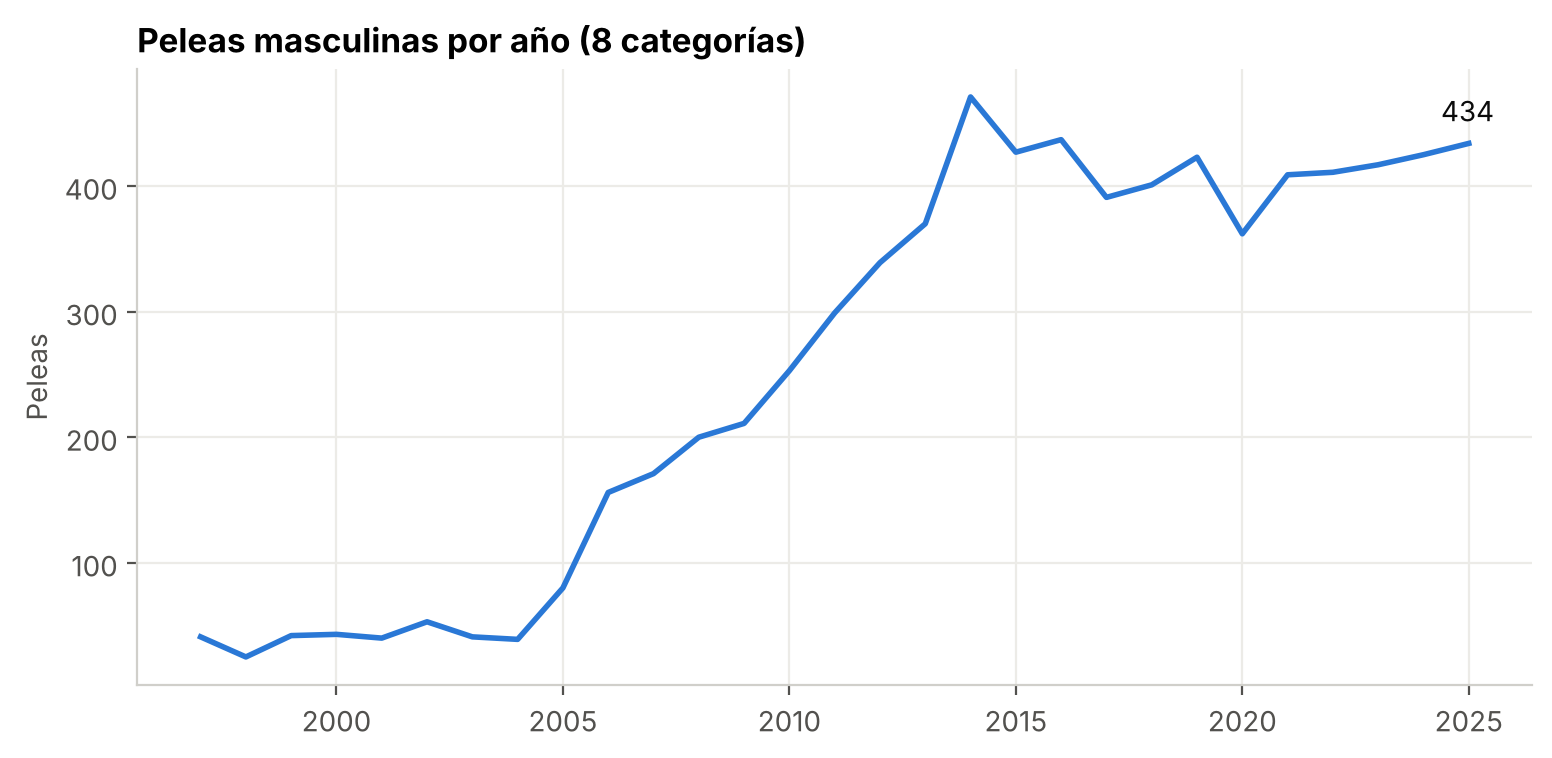

In [12]:
por_anio = pm.groupby(pm["fecha"].dt.year).size()          # contamos peleas por año
por_anio = por_anio[por_anio.index < FECHA_CORTE.year]     # sacamos el año actual porque todavía no terminó
fig, ax = plt.subplots()                                   # creamos un gráfico vacío
ax.plot(por_anio.index, por_anio.values, color=AZUL, linewidth=2)  # dibujamos la línea: año vs. cantidad
ax.set_title("Peleas masculinas por año (8 categorías)")   # título
ax.set_ylabel("Peleas")                                    # nombre del eje Y
ax.set_xlabel("")                                          # el eje X (años) no necesita nombre
ultimo_anio, ultimo_valor = por_anio.index[-1], por_anio.iloc[-1]  # el último punto de la línea
ax.annotate(f"{ultimo_valor}", (ultimo_anio, ultimo_valor),        # escribimos su valor al lado
            textcoords="offset points", xytext=(-10, 8), color=TINTA)  # un poco arriba y a la izquierda
plt.show()                                                 # mostramos el gráfico

**Lectura:** desde 2014 la UFC hace **alrededor de 400 peleas masculinas por año** (unas 35 por mes; solo 2020, por la pandemia, quedó bastante abajo).
Ningún fan puede seguir todo eso de memoria: es la razón de ser de un ranking con datos.

### 3.2 Peleas por categoría en los últimos 3 años

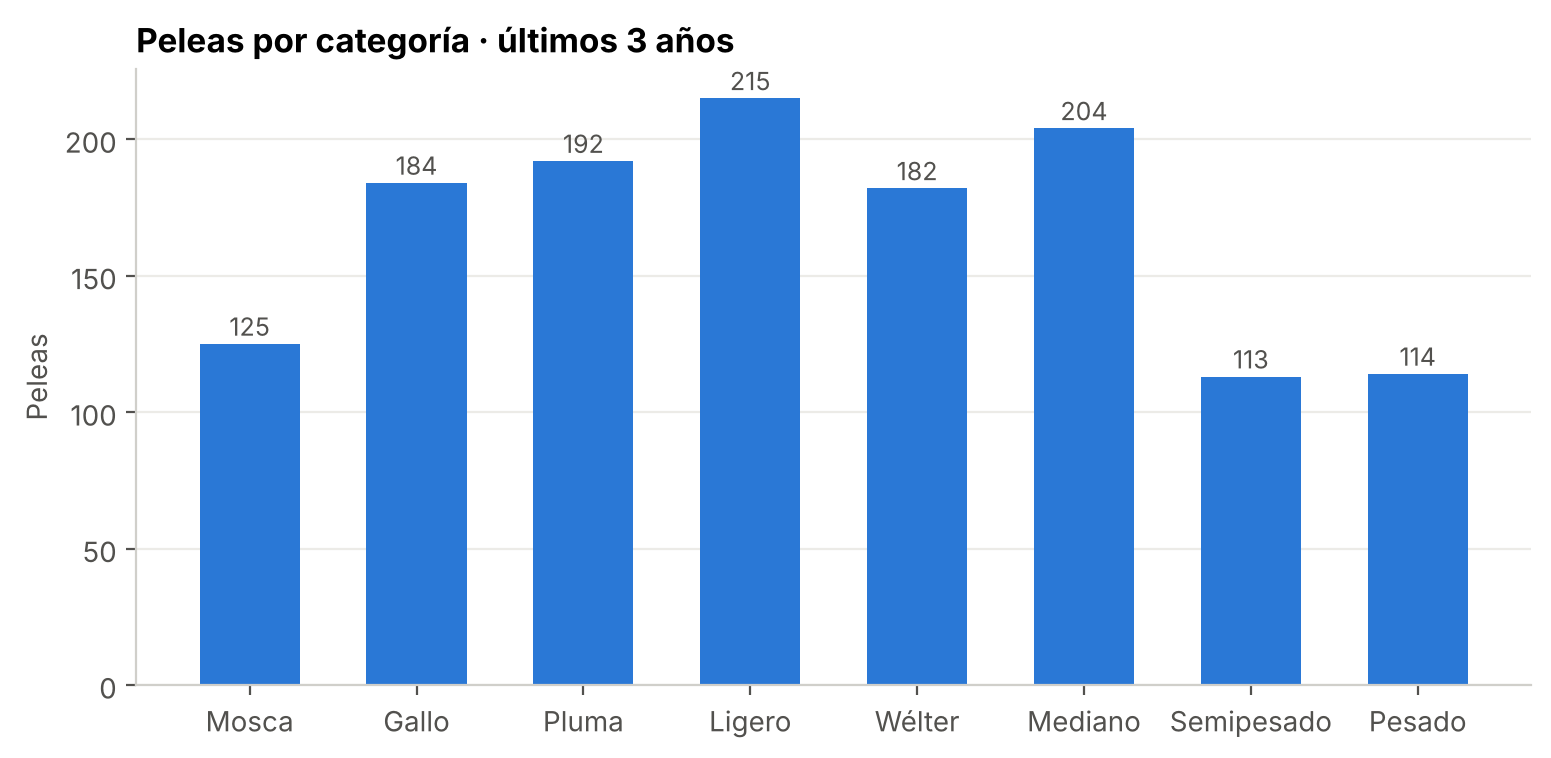

In [13]:
hace_3_anios = FECHA_CORTE - pd.DateOffset(years=3)            # la fecha de 3 años antes del corte
recientes = pm[pm["fecha"] > hace_3_anios]                     # solo las peleas de los últimos 3 años
por_div = recientes["division"].value_counts().reindex(MASCULINAS)  # peleas por categoría, en orden de peso
fig, ax = plt.subplots()                                       # gráfico vacío
ax.bar(por_div.index, por_div.values, color=AZUL, width=0.6)   # una barra por categoría
for i, v in enumerate(por_div.values):                         # recorremos cada barra (i = posición, v = valor)
    ax.text(i, v + 3, str(v), ha="center", color=TINTA_2, fontsize=9)  # escribimos el número arriba de la barra
ax.set_title("Peleas por categoría · últimos 3 años")          # título
ax.set_ylabel("Peleas")                                        # nombre del eje Y
ax.grid(axis="x", visible=False)                               # quitamos las líneas verticales de la grilla
plt.show()                                                     # mostramos el gráfico

**Lectura:** las categorías no tienen el mismo volumen. Ligero y Pluma tienen mucho más
movimiento que Semipesado o Pesado. **Implicancia:** el ranking no puede exigir la misma
cantidad de peleas en todas las categorías.

### 3.3 ¿Cómo se gana en cada categoría?

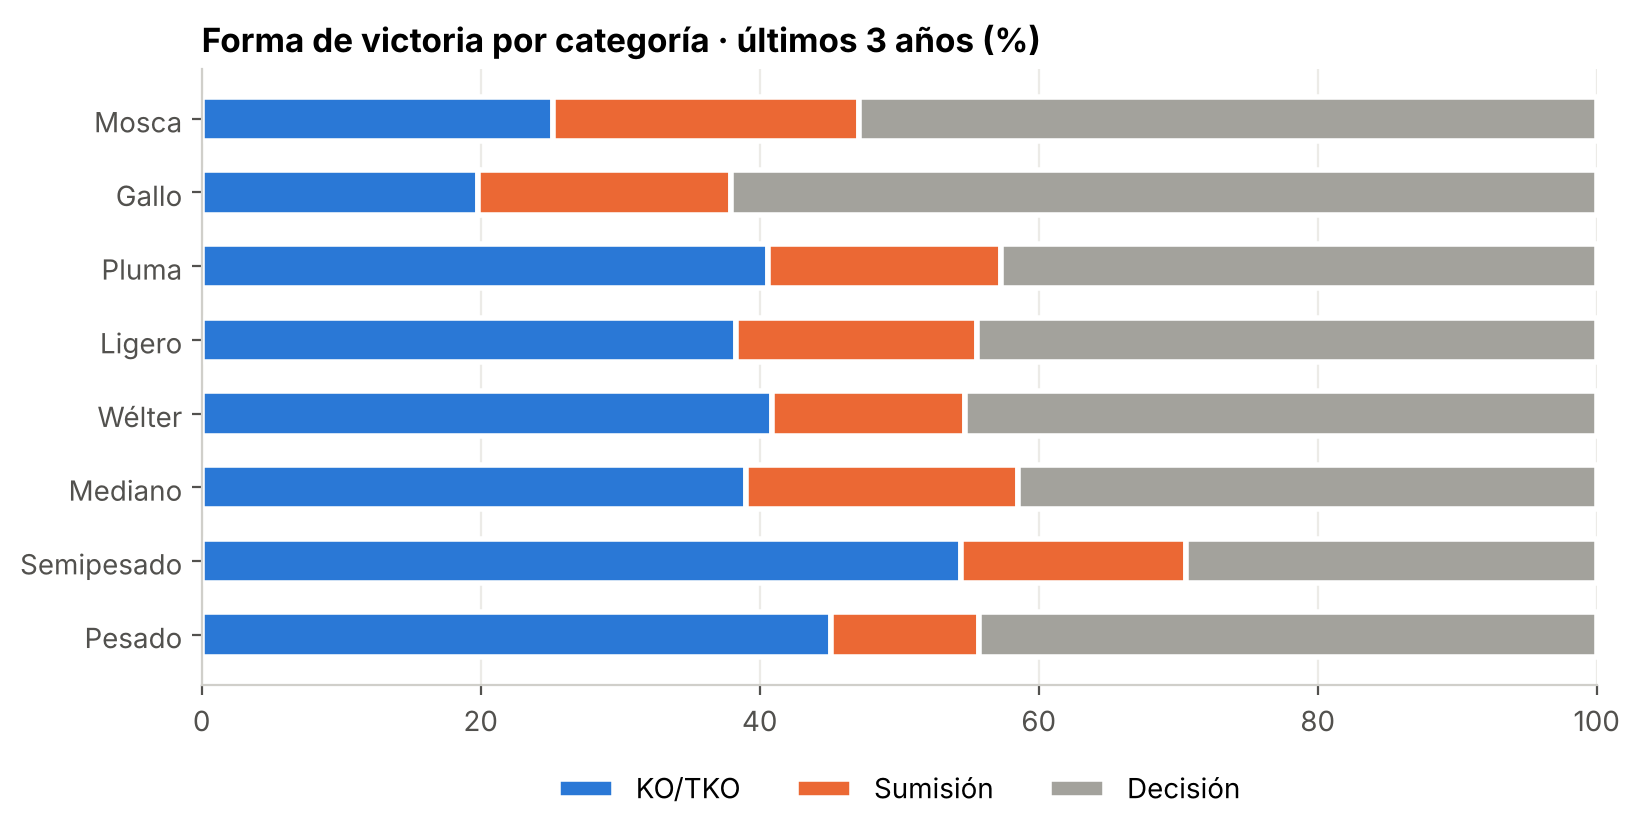

metodo_grupo,KO/TKO,Sumisión,Decisión
division,,,
Mosca,25.2,22.0,52.8
Gallo,19.8,18.1,62.1
Pluma,40.6,16.7,42.7
Ligero,38.3,17.3,44.4
Wélter,40.9,13.8,45.3
Mediano,39.0,19.5,41.5
Semipesado,54.5,16.1,29.5
Pesado,45.1,10.6,44.2


In [14]:
con_metodo = recientes[recientes["metodo_grupo"] != "Otro"]    # sacamos descalificaciones, anuladas, etc.
proporciones = (con_metodo.groupby("division")["metodo_grupo"] # por cada categoría...
                .value_counts(normalize=True))                 # ...qué proporción terminó de cada forma
metodos = proporciones.unstack()                               # pasamos a tabla: filas = categorías, columnas = métodos
metodos = metodos.reindex(MASCULINAS)                          # ordenamos las filas de más liviana a más pesada
metodos = metodos[["KO/TKO", "Sumisión", "Decisión"]] * 100    # ordenamos columnas y pasamos a porcentaje

fig, ax = plt.subplots()                                       # gráfico vacío
izq = 0                                                        # dónde empieza cada tramo de la barra (arranca en 0)
for col, color in zip(metodos.columns, [AZUL, NARANJA, GRIS]): # un tramo por método, cada uno con su color
    ax.barh(metodos.index, metodos[col], left=izq, color=color, label=col,  # barra horizontal desde "izq"
            height=0.6, edgecolor="white", linewidth=2)        # borde blanco para separar los tramos
    izq = izq + metodos[col]                                   # el próximo tramo empieza donde terminó este
ax.set_title("Forma de victoria por categoría · últimos 3 años (%)")  # título
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)  # leyenda abajo, en una fila
ax.invert_yaxis()                                              # que "Mosca" quede arriba y "Pesado" abajo
ax.grid(axis="y", visible=False)                               # sin líneas horizontales de grilla
ax.set_xlim(0, 100)                                            # el eje X va de 0% a 100%
plt.show()                                                     # mostramos el gráfico
metodos.round(1)                                               # y también la tabla con los porcentajes

**Lectura:** en **Semipesado** más de la mitad de las peleas termina por KO (55%), mientras que
en **Gallo** y **Mosca** la mayoría se define por decisión (62% y 53%). **Implicancia:** si el ranking premia los nocauts, tiene que
hacerlo *dentro* de cada categoría. Si no, un pesado siempre parecería "mejor" que un mosca.

## 4. Actividad: ¿quién está realmente compitiendo?

Para un fan, un ranking que incluye gente que no pelea hace dos años pierde credibilidad.
Medimos los **días desde la última pelea** de cada peleador.

In [15]:
ordenado = lm.sort_values("fecha")                              # ordenamos todas las peleas por fecha
ultima = ordenado.groupby("peleador").tail(1).copy()            # nos quedamos con la ÚLTIMA pelea de cada peleador
ultima["dias_inactivo"] = (FECHA_CORTE - ultima["fecha"]).dt.days  # días entre esa pelea y la fecha de corte

columnas_activos = {}                                           # diccionario: una columna por ventana de tiempo
for meses in (12, 18, 24):                                      # probamos tres ventanas: 12, 18 y 24 meses
    dentro = ultima[ultima["dias_inactivo"] <= meses * 30.4]    # peleadores que pelearon dentro de esa ventana
    columnas_activos[f"≤ {meses} meses"] = dentro.groupby("division").size()  # cuántos hay por categoría
activos = pd.DataFrame(columnas_activos).reindex(MASCULINAS)    # tabla final, en orden de peso
activos                                                         # la mostramos

,≤ 12 meses,≤ 18 meses,≤ 24 meses
division,,,
Mosca,44,50,57
Gallo,78,89,100
Pluma,89,101,110
Ligero,88,102,112
Wélter,75,86,94
Mediano,76,81,86
Semipesado,47,54,56
Pesado,52,59,65


**Lectura:** cada categoría tiene entre 44 (Mosca) y 89 (Pluma) peleadores que pelearon en el último año.
El ranking oficial muestra 15 por categoría, así que hay material de sobra para elegir.
La categoría se asigna según **la última pelea**.

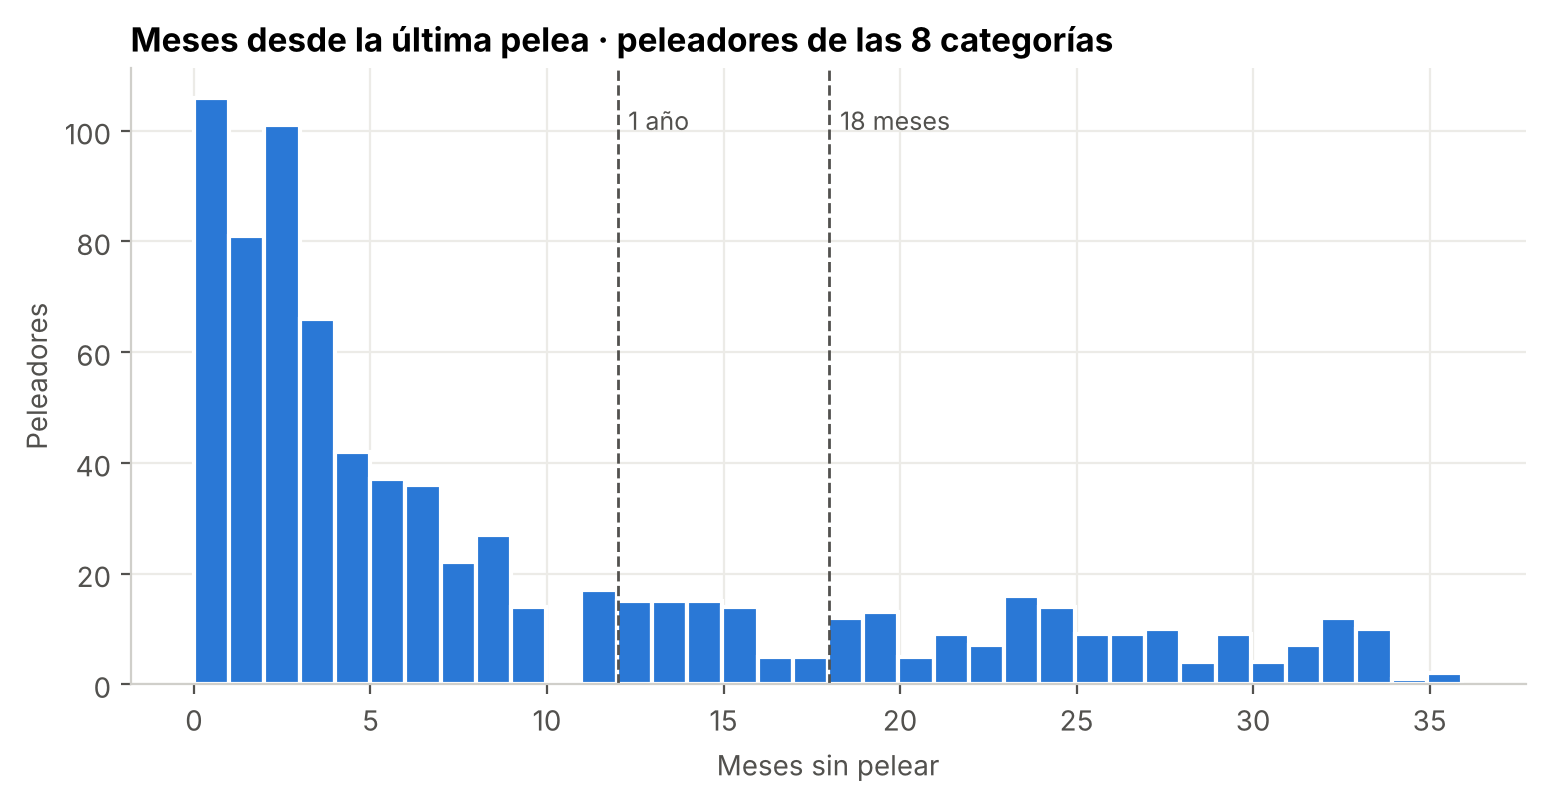

In [16]:
recientes_ult = ultima[ultima["dias_inactivo"] <= 3 * 365]      # peleadores que pelearon en los últimos 3 años
meses_inactivo = recientes_ult["dias_inactivo"] / 30.4          # pasamos días a meses
fig, ax = plt.subplots()                                        # gráfico vacío
ax.hist(meses_inactivo, bins=36, color=AZUL,                    # histograma: 36 barras, una por mes
        edgecolor="white", linewidth=1.5)                       # borde blanco entre barras
for m, txt in [(12, "1 año"), (18, "18 meses")]:                # dos líneas de referencia
    ax.axvline(m, color=TINTA_2, linestyle="--", linewidth=1)   # línea vertical punteada en ese mes
    ax.text(m + 0.3, ax.get_ylim()[1] * 0.9, txt,               # etiqueta al lado de la línea, cerca de arriba
            color=TINTA_2, fontsize=9)
ax.set_title("Meses desde la última pelea · peleadores de las 8 categorías")  # título
ax.set_xlabel("Meses sin pelear")                               # nombre del eje X
ax.set_ylabel("Peleadores")                                     # nombre del eje Y
plt.show()                                                      # mostramos el gráfico

**Lectura:** lo habitual es pelear cada 4 a 8 meses (la mediana entre peleas es de unos 6 meses). Pasado el año la barra cae mucho: quien está
ahí ya es una excepción (lesión, suspensión, retiro). **Decisión propuesta para la Etapa 2:**
para entrar al ranking hay que haber peleado en los **últimos 18 meses**.

### 4.1 Peleadores que cambiaron de categoría

In [17]:
activos_18 = ultima.loc[ultima["dias_inactivo"] <= 548, "peleador"]  # nombres de los activos (≤ 18 meses = 548 días)
es_activo = lm["peleador"].isin(activos_18)                     # filas de peleas de esos peleadores
es_reciente = lm["fecha"] > FECHA_CORTE - pd.DateOffset(years=3)  # filas de los últimos 3 años
tres_anios = lm[es_activo & es_reciente]                        # las peleas que cumplen las dos cosas
n_div = tres_anios.groupby("peleador")["division"].nunique()    # en cuántas categorías distintas peleó cada uno
cambiaron = (n_div > 1).sum()                                   # cuántos pelearon en más de una
porcentaje = (n_div > 1).mean()                                 # qué proporción representan
print(f"Peleadores activos que pelearon en más de una categoría (últimos 3 años): "
      f"{cambiaron} de {len(n_div)} ({porcentaje:.0%})")        # mostramos el resultado

Peleadores activos que pelearon en más de una categoría (últimos 3 años): 102 de 622 (16%)


**Implicancia:** cerca de 1 de cada 6 activos se movió de categoría. Hay que decidir si
una victoria en otra categoría cuenta. **Propuesta:** cuenta, con menos peso.

### 4.2 ¿Qué homónimos (H5) siguen activos?

In [18]:
repetidos = fisico.loc[fisico["FIGHTER"].duplicated(), "FIGHTER"]  # los nombres que aparecen más de una vez
nombres_repetidos = set(repetidos.str.strip())                  # como conjunto, sin espacios
es_homonimo = ultima["peleador"].isin(nombres_repetidos)        # ¿el peleador tiene un nombre repetido?
esta_activo = ultima["dias_inactivo"] <= 548                    # ¿peleó en los últimos 18 meses?
afectados = ultima[es_homonimo & esta_activo]                   # los que cumplen las dos condiciones
afectados[["peleador", "division", "fecha", "dias_inactivo"]]   # los mostramos

,peleador,division,fecha,dias_inactivo
17301,Victor Valenzuela,Wélter,2026-04-25,203.0
2288,Bruno Silva,Mosca,2026-06-06,161.0
12320,Mike Davis,Ligero,2026-07-25,112.0
7791,Jean Silva,Pluma,2026-09-12,63.0
1261,Anthony Romero,Pluma,2026-10-03,42.0


**Lectura:** 5 de los 9 nombres repetidos tienen un peleador activo hoy (por ejemplo Bruno Silva en Mosca
y Jean Silva en Pluma).
El H5 **no es teórico: afecta al ranking actual**. Es una de las primeras cosas a resolver.

## 5. Conclusiones para el diagnóstico (Etapa 1)

**Calidad de datos.** La fuente es completa y está al día, pero no se puede usar "tal cual".
Encontramos 7 problemas concretos (H1–H7). Dos de ellos (duplicados y homónimos)
**falsean resultados sin dar error**, y son los más peligrosos.

**Stack actual del grupo.** Hoy no existe: la información está en la memoria de cada uno,
en la web de la UFC y en el grupo de WhatsApp. **Propuesta:** un flujo simple y repetible,
`descarga → limpieza → tablas limpias → ranking`, que se vuelve a correr después de cada evento.

**Lo que el EDA ya define para el ranking (Etapa 2):**

| Decisión | Evidencia |
|---|---|
| Solo resultados de peleas, sin datos físicos | H4: faltan muchos datos físicos |
| Contar cada pelea una sola vez | H2 |
| Identificar bien a cada peleador | H5 y 4.2 |
| Estar activo: haber peleado en los últimos 18 meses | Sección 4 |
| Premiar finalizaciones comparando dentro de cada categoría | Sección 3.3 |
| Una pelea en otra categoría cuenta, con menos peso | Sección 4.1 |
| Empate = ½ victoria, No Contest = 0 | H7 |

**Prioridad:** primero arreglar la base de datos (el problema), después construir el
ranking (la propuesta). Un ranking calculado sobre datos con duplicados y homónimos
repetiría justo lo que le criticamos a los rankings actuales: resultados que no se pueden explicar.